# Risk Alert Classifier: Predicting High-Risk Customers

End-to-end binary classification project: **Risk Status** (0 = Low Risk, 1 = High Risk) from customer
demographic, transaction-activity and credit-behaviour data.

**Business goal:** flag as many genuinely high-risk customers as possible. A missed high-risk customer
(false negative) is far more expensive than an unnecessary review (false positive), so the final model is
selected to **minimise false negatives** while keeping precision at a workable level.

| Part | Topic |
|---|---|
| A | Conceptual understanding (theory) |
| B | Dataset understanding and preparation |
| C | Baseline Logistic Regression |
| D | Handling imbalanced data |
| E | Decision Tree and Random Forest |
| F | Hyperparameter tuning |
| G | ROC analysis and final model selection |
| H | Final analysis and reporting |

---
# Part A: Conceptual Understanding (Theory)

**1. What is Logistic Regression and why is it suitable for classification?**
Logistic Regression models the probability of the positive class as `p = 1 / (1 + e^-(b0 + b1x1 + ... + bkxk))`,
i.e. a linear combination of features squashed through the sigmoid so the output lies in (0, 1). Thresholding that
probability (usually 0.5) gives a class label. It suits classification because it outputs calibrated probabilities,
trains fast, and its coefficients are interpretable as log-odds (exp(b) = odds ratio).

**2. Why is accuracy alone insufficient? Explain classification performance metrics.**
Accuracy = (TP + TN) / total ignores *which* mistakes are made. On a dataset that is 88% Low Risk, a model that
predicts "Low Risk" for everyone scores 88% accuracy yet catches zero high-risk customers. Metrics built from the
confusion matrix (precision, recall, F1, specificity) and ranking metrics (AUC-ROC) expose how well each class is
handled and the trade-off between the two error types.

**3. Define Type-I and Type-II error in the context of risk prediction.**
**Type-I error = False Positive:** a Low-Risk customer is flagged High Risk (wasted review effort, customer friction).
**Type-II error = False Negative:** a High-Risk customer is classed as Low Risk (undetected default or fraud loss).
In risk prediction Type-II errors are usually the costlier ones.

**4. Explain Precision, Recall, F1-Score, TPR and FPR.**
**Precision** = TP / (TP + FP): of the customers flagged high risk, how many truly are.
**Recall = TPR** = TP / (TP + FN): of all truly high-risk customers, how many we caught.
**F1** = 2PR / (P + R): harmonic mean of precision and recall (punishes imbalance between them).
**FPR** = FP / (FP + TN): share of low-risk customers wrongly flagged (= 1 - specificity).

**5. What is AUC-ROC and how does it help in evaluating classifiers?**
The ROC curve plots TPR against FPR as the decision threshold sweeps from 1 to 0. AUC is the area under that curve:
the probability that a randomly chosen positive is scored higher than a randomly chosen negative (0.5 = random,
1.0 = perfect). It is threshold-independent, so it compares models' ranking quality fairly, and the curve helps
pick an operating threshold.

**6. Why does imbalanced data create problems in classification models?**
Training minimises overall error, so the majority class dominates the loss and the model learns to favour it. The
minority class (here High Risk) is under-predicted: recall collapses while accuracy still looks excellent. Decision
boundaries, tree splits and probability estimates are all biased toward the majority, so we need resampling,
class weights or threshold adjustment, and metrics other than accuracy.

---
# Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV,
                                     GridSearchCV, cross_val_predict)
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             make_scorer)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def save_fig(name):
    """Save the current figure to ./figures (used as README screenshots) and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Setup complete")

Setup complete


---
# Part B: Dataset Understanding and Preparation

In [2]:
df = pd.read_csv("data/risk_alert_classifier_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   str    
 3   region                     4498 non-null   str    
 4   employment_type            4456 non-null   str    
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64  
 14  fai

## Exploratory look: target balance and missingness

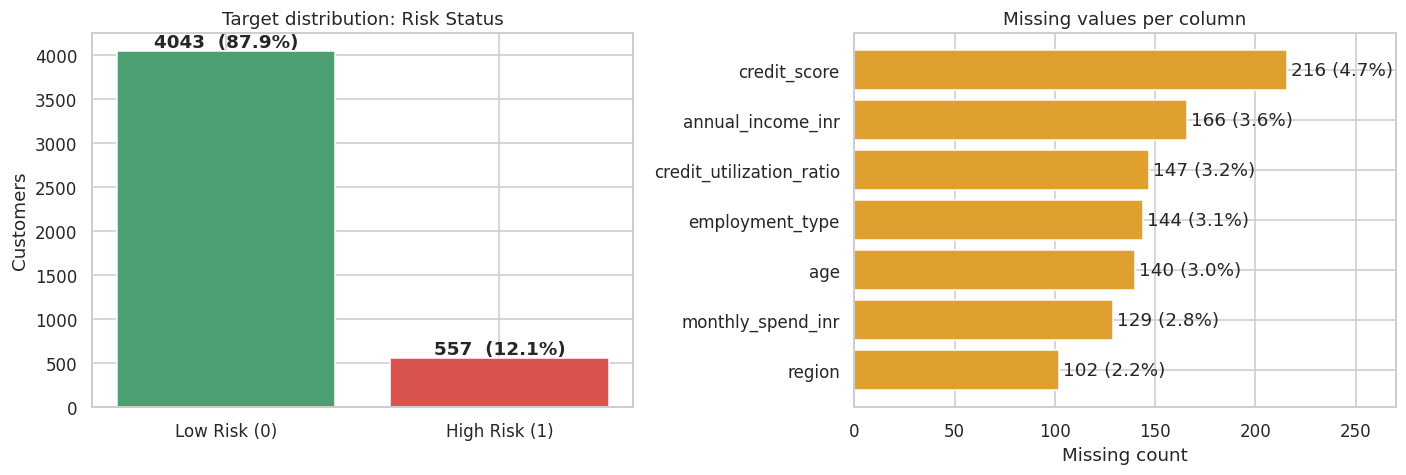

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = df["risk_status"].value_counts().sort_index()
axes[0].bar(["Low Risk (0)", "High Risk (1)"], counts.values, color=["#4C9F70", "#D9534F"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 40, f"{v}  ({v / len(df):.1%})", ha="center", fontweight="bold")
axes[0].set_title("Target distribution: Risk Status")
axes[0].set_ylabel("Customers")

miss = df.isna().sum()
miss = miss[miss > 0].sort_values()
axes[1].barh(miss.index, miss.values, color="#E0A030")
for i, v in enumerate(miss.values):
    axes[1].text(v + 2, i, f"{v} ({v / len(df):.1%})", va="center")
axes[1].set_title("Missing values per column")
axes[1].set_xlabel("Missing count")
axes[1].set_xlim(0, miss.max() * 1.25)
plt.tight_layout()
save_fig("01_target_and_missing")

**Interpretation.** The target is imbalanced: 4,043 Low-Risk customers (87.9%) vs 557 High-Risk (12.1%), roughly 7.3 : 1.
Seven columns have missing values, between 2.2% (`region`) and 4.7% (`credit_score`) of rows, so no column is badly affected and
imputation (rather than dropping columns or rows) is appropriate.

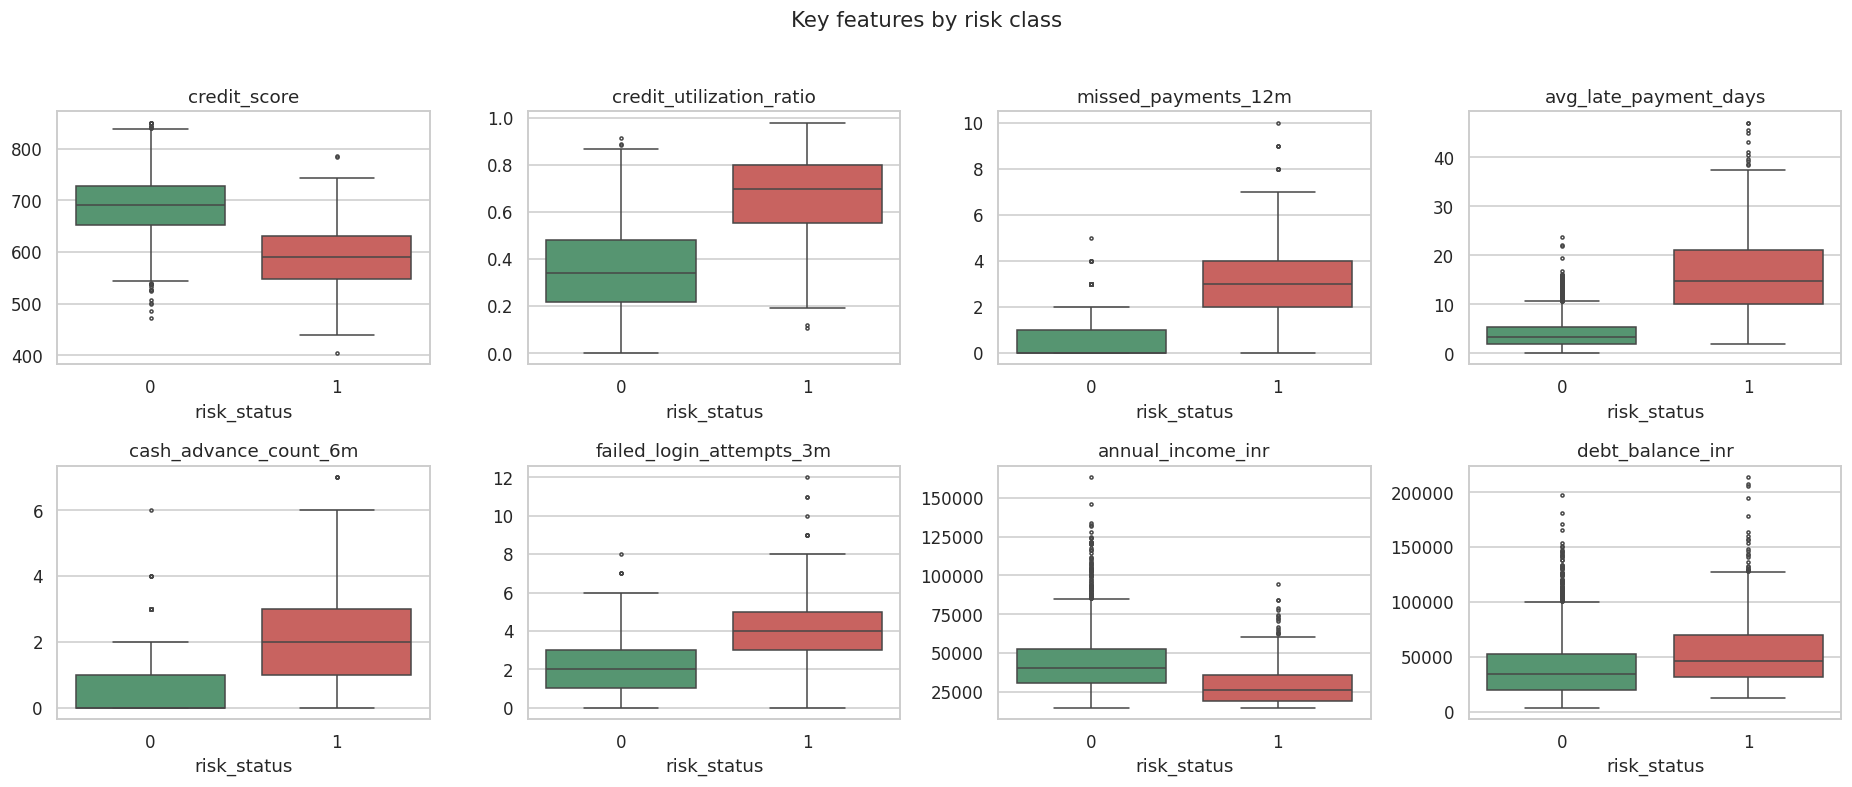

In [5]:
num_for_plot = ["credit_score", "credit_utilization_ratio", "missed_payments_12m", "avg_late_payment_days",
                "cash_advance_count_6m", "failed_login_attempts_3m", "annual_income_inr", "debt_balance_inr"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), num_for_plot):
    sns.boxplot(data=df, x="risk_status", y=col, hue="risk_status", palette=["#4C9F70", "#D9534F"],
                legend=False, ax=ax, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("risk_status")
    ax.set_ylabel("")
plt.suptitle("Key features by risk class", y=1.02, fontsize=14)
plt.tight_layout()
save_fig("02_feature_by_class")

**Interpretation.** High-risk customers clearly differ on the credit-behaviour features: they have more late-payment days
(mean 16.3 vs 4.1), more missed payments (3.3 vs 0.6), higher credit utilisation (0.67 vs 0.36), more cash advances and failed logins,
and lower credit scores (589 vs 690) and income. Features such as `age`, `account_tenure_months` and `monthly_transaction_count`
look the same for both classes and are expected to carry little signal.

## Task 7: Identify input features and target variable

* `customer_id` is a row identifier with no predictive meaning, so it is **dropped**.
* `last_transaction_date` is a raw date. It is converted to **`days_since_last_txn`** (recency, measured from the
  day after the latest date in the data).
* `risk_status` is the **target**.

In [6]:
ref_date = pd.to_datetime(df["last_transaction_date"]).max() + pd.Timedelta(days=1)
df["days_since_last_txn"] = (ref_date - pd.to_datetime(df["last_transaction_date"])).dt.days

TARGET = "risk_status"
DROP = ["customer_id", "last_transaction_date", TARGET]
X = df.drop(columns=DROP)
y = df[TARGET]

cat_cols = ["gender", "region", "employment_type"]
num_cols = [c for c in X.columns if c not in cat_cols]

feature_table = pd.DataFrame({
    "Feature": X.columns,
    "Type": ["categorical" if c in cat_cols else "numeric" for c in X.columns],
    "Group": [("Demographic" if c in ["age", "gender", "region", "employment_type", "annual_income_inr"] else
               "Credit behaviour" if c in ["credit_score", "credit_utilization_ratio", "missed_payments_12m",
                                           "avg_late_payment_days", "cash_advance_count_6m", "debt_balance_inr"] else
               "Transaction / activity") for c in X.columns],
})
print(f"{X.shape[1]} input features ({len(num_cols)} numeric, {len(cat_cols)} categorical); target = '{TARGET}'")
feature_table

17 input features (14 numeric, 3 categorical); target = 'risk_status'


,Feature,Type,Group
0,age,numeric,Demographic
1,gender,categorical,Demographic
2,region,categorical,Demographic
3,employment_type,categorical,Demographic
4,annual_income_inr,numeric,Demographic
5,credit_score,numeric,Credit behaviour
6,credit_utilization_ratio,numeric,Credit behaviour
7,missed_payments_12m,numeric,Credit behaviour
8,avg_late_payment_days,numeric,Credit behaviour
9,monthly_transaction_count,numeric,Transaction / activity


### Leakage check

Before modelling, each numeric feature is scored on its own (single-feature AUC). A value near 1.0 would mean a
feature almost *is* the label and might be leaking the answer.

In [7]:
rows = []
for c in num_cols:
    ok = X[c].notna()
    a = roc_auc_score(y[ok], X.loc[ok, c])
    rows.append((c, max(a, 1 - a), "higher value = more risk" if a >= .5 else "lower value = more risk"))
single = pd.DataFrame(rows, columns=["Feature", "Single-feature AUC", "Direction"]).sort_values(
    "Single-feature AUC", ascending=False).reset_index(drop=True)
single.style.format({"Single-feature AUC": "{:.3f}"}).bar(subset=["Single-feature AUC"], vmin=0.5, vmax=1, color="#9ec5e8")

,Feature,Single-feature AUC,Direction
0,avg_late_payment_days,0.953,higher value = more risk
1,missed_payments_12m,0.915,higher value = more risk
2,credit_score,0.895,lower value = more risk
3,credit_utilization_ratio,0.886,higher value = more risk
4,cash_advance_count_6m,0.845,higher value = more risk
5,failed_login_attempts_3m,0.830,higher value = more risk
6,annual_income_inr,0.756,lower value = more risk
7,complaints_last_6m,0.726,higher value = more risk
8,debt_balance_inr,0.654,higher value = more risk
9,monthly_spend_inr,0.531,lower value = more risk


**Interpretation.** No single feature gives the answer away: the strongest, `avg_late_payment_days`, has a single-feature AUC of 0.953,
and several features sit near 0.5 (no signal alone). `customer_id` was removed up front. Risk is therefore determined by the
*combination* of about nine credit-behaviour variables, which is exactly what a multivariate model should learn. This also explains
the very high scores seen later (see the caution in Part C).

## Task 8: Stratified train-test split

An 80/20 split with `stratify=y` keeps the High-Risk share identical in both sets. The split is done **before**
any imputation, scaling or resampling so that nothing about the test set leaks into training.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

dist = pd.DataFrame({
    "Full data": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).T.rename(columns={0: "Low Risk (0)", 1: "High Risk (1)"})
dist["n rows"] = [len(y), len(y_train), len(y_test)]
dist["High-risk count"] = [y.sum(), y_train.sum(), y_test.sum()]
print("Class distribution is preserved across the split:")
dist.style.format({"Low Risk (0)": "{:.2%}", "High Risk (1)": "{:.2%}"})

Class distribution is preserved across the split:


risk_status,Low Risk (0),High Risk (1),n rows,High-risk count
Full data,87.89%,12.11%,4600,557
Train,87.88%,12.12%,3680,446
Test,87.93%,12.07%,920,111


## Task 9: Missing values and multivariate KNN imputation

Missing values are present in 7 columns (see chart above). They are filled with **`KNNImputer`**, which estimates a
missing value from the `k` most similar customers using *all* the other features (multivariate imputation).

Implementation details that matter:
1. Categorical columns are one-hot encoded first; rows with a missing category get `NaN` in that column's dummies
   so the imputer can estimate them like any other value. After imputation the highest dummy per group wins.
2. KNN is distance based, so features are **standardised before imputing** (otherwise income in rupees would
   swamp ratios between 0 and 1).
3. The scaler and imputer are **fitted on the training set only** and then applied to the test set.

In [9]:
print("Missing values BEFORE imputation (train / test):")
before = pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()})
before = before[(before.train > 0) | (before.test > 0)]
before["train %"] = (before["train"] / len(X_train) * 100).round(1)
before

Missing values BEFORE imputation (train / test):


,train,test,train %
age,116,24,3.2
region,78,24,2.1
employment_type,115,29,3.1
annual_income_inr,132,34,3.6
credit_score,181,35,4.9
credit_utilization_ratio,118,29,3.2
monthly_spend_inr,110,19,3.0


In [10]:
def one_hot_with_nan(frame, columns=None):
    """One-hot encode categoricals; rows whose category is missing get NaN across that group's dummies."""
    parts = [frame[num_cols].copy()]
    for c in cat_cols:
        d = pd.get_dummies(frame[c], prefix=c, dtype=float)
        d.loc[frame[c].isna(), :] = np.nan
        parts.append(d)
    out = pd.concat(parts, axis=1)
    if columns is not None:
        out = out.reindex(columns=columns, fill_value=0.0)
    return out


Xtr_enc = one_hot_with_nan(X_train)
Xte_enc = one_hot_with_nan(X_test, columns=Xtr_enc.columns)

scaler_imp = StandardScaler().fit(Xtr_enc)                       # NaN-aware, fitted on train only
knn_imputer = KNNImputer(n_neighbors=5).fit(scaler_imp.transform(Xtr_enc))

INT_COLS = ["age", "credit_score"]
RATIO_COLS = ["credit_utilization_ratio"]


def impute(enc):
    arr = knn_imputer.transform(scaler_imp.transform(enc))
    arr = scaler_imp.inverse_transform(arr)
    out = pd.DataFrame(arr, columns=enc.columns, index=enc.index)
    for c in cat_cols:                                           # snap dummies back to a valid one-hot row
        grp = [k for k in out.columns if k.startswith(c + "_")]
        out[grp] = np.eye(len(grp))[out[grp].values.argmax(axis=1)]
    out[INT_COLS] = out[INT_COLS].round()
    out[RATIO_COLS] = out[RATIO_COLS].clip(0, 1)
    return out


X_train_imp = impute(Xtr_enc)
X_test_imp = impute(Xte_enc)

print("Missing values AFTER imputation  ->  train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))
print("Final feature matrix:", X_train_imp.shape, "(train),", X_test_imp.shape, "(test)")
X_train_imp.head()

Missing values AFTER imputation  ->  train: 0 | test: 0
Final feature matrix: (3680, 27) (train), (920, 27) (test)


,age,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,debt_balance_inr,days_since_last_txn,gender_Female,gender_Male,gender_Other,region_Central,region_East,region_North,region_South,region_West,employment_type_Retired,employment_type_Salaried,employment_type_Self-Employed,employment_type_Student,employment_type_Unemployed
2264,25.0,54692.0,659.0,0.044,0.0,0.7,34.0,13853.0,3.0,-5.551115e-17,0.0,40.0,45179.0,63.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3795,34.0,42474.0,582.0,0.049,3.0,1.0,67.0,15540.0,0.0,-5.551115e-17,2.0,60.0,47471.0,61.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3968,27.0,57508.0,550.0,0.823,4.0,8.9,73.0,31818.0,6.0,1.000000e+00,3.0,30.0,52554.0,78.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3555,35.0,81304.0,729.0,0.149,0.0,6.1,66.0,31757.0,1.0,-5.551115e-17,0.0,9.0,106467.0,64.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3219,40.0,41647.0,604.0,0.161,1.0,3.4,40.0,15351.0,1.0,-5.551115e-17,2.0,115.0,49710.0,57.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


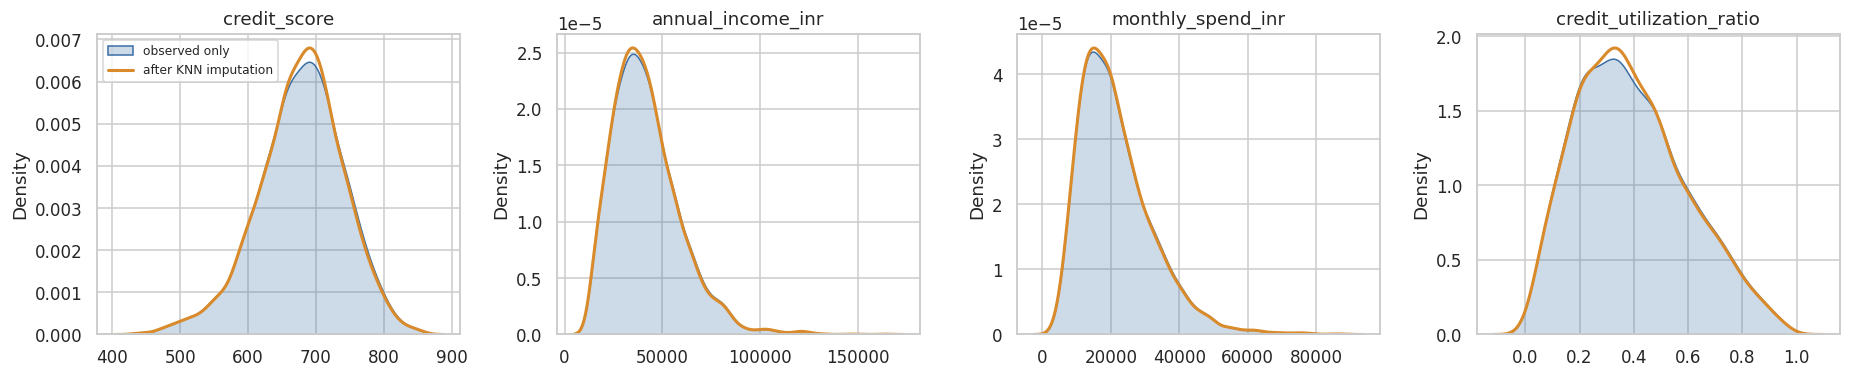

In [11]:
# Sanity check: imputation should not distort the distributions of the filled columns
cols_chk = ["credit_score", "annual_income_inr", "monthly_spend_inr", "credit_utilization_ratio"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, c in zip(axes, cols_chk):
    sns.kdeplot(Xtr_enc[c].dropna(), ax=ax, label="observed only", color="#3B6EA5", fill=True, alpha=.25)
    sns.kdeplot(X_train_imp[c], ax=ax, label="after KNN imputation", color="#D98A2B", lw=2)
    ax.set_title(c); ax.set_xlabel("")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig("03_imputation_check")

**Interpretation.** Imputation preserves the shape of each distribution: e.g. mean credit score 677.6 -> 677.7 and mean income
41,924 -> 41,831, with a slight narrowing of the spread (about 1-2%), which is the normal smoothing effect of averaging neighbours.
All 7 columns have 0 missing values afterwards in both train and test, giving a 27-column numeric feature matrix.

In [12]:
# Scaled copies for the distance / gradient based models (Logistic Regression, SMOTE, ADASYN).
# Tree models use the unscaled matrices (scaling does not change tree splits).
scaler = StandardScaler().fit(X_train_imp)
X_train_s = scaler.transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)
y_train_arr, y_test_arr = y_train.to_numpy(), y_test.to_numpy()

# ---- shared evaluation helpers -------------------------------------------------
RESULTS = []      # one row per evaluated model (test set)
PROBS = {}        # test-set probabilities, kept for the ROC analysis in Part G


def evaluate(name, y_true, y_pred, y_prob, store=True):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    row = {"Model": name,
           "Accuracy": accuracy_score(y_true, y_pred),
           "Precision": precision_score(y_true, y_pred, zero_division=0),
           "Recall": recall_score(y_true, y_pred),
           "F1": f1_score(y_true, y_pred),
           "F2": fbeta_score(y_true, y_pred, beta=2),
           "AUC": roc_auc_score(y_true, y_prob),
           "TN": tn, "FP (Type-I)": fp, "FN (Type-II)": fn, "TP": tp}
    if store:
        RESULTS.append(row)
        PROBS[name] = y_prob
    return row


def plot_cm(y_true, y_pred, title, ax=None):
    cm = confusion_matrix(y_true, y_pred)
    ax = ax or plt.gca()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 15},
                xticklabels=["Pred Low", "Pred High"], yticklabels=["Actual Low", "Actual High"])
    ax.set_title(title)
    return cm


FMT = {"Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "F2": "{:.3f}", "AUC": "{:.3f}"}
print("Preparation finished. Train:", X_train_s.shape, "Test:", X_test_s.shape)

Preparation finished. Train: (3680, 27) Test: (920, 27)


---
# Part C: Baseline Classification Model

## Task 10: Logistic Regression baseline (default settings, no balancing)

In [13]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train_arr)
lr_pred = lr.predict(X_test_s)
lr_prob = lr.predict_proba(X_test_s)[:, 1]
base = evaluate("Logistic Regression (baseline)", y_test_arr, lr_pred, lr_prob)
print("Baseline fitted. Test AUC = %.3f" % base["AUC"])

Baseline fitted. Test AUC = 1.000


## Task 11: Confusion matrix, accuracy, precision, recall, F1

               precision    recall  f1-score   support

 Low Risk (0)      1.000     1.000     1.000       809
High Risk (1)      1.000     1.000     1.000       111

     accuracy                          1.000       920
    macro avg      1.000     1.000     1.000       920
 weighted avg      1.000     1.000     1.000       920



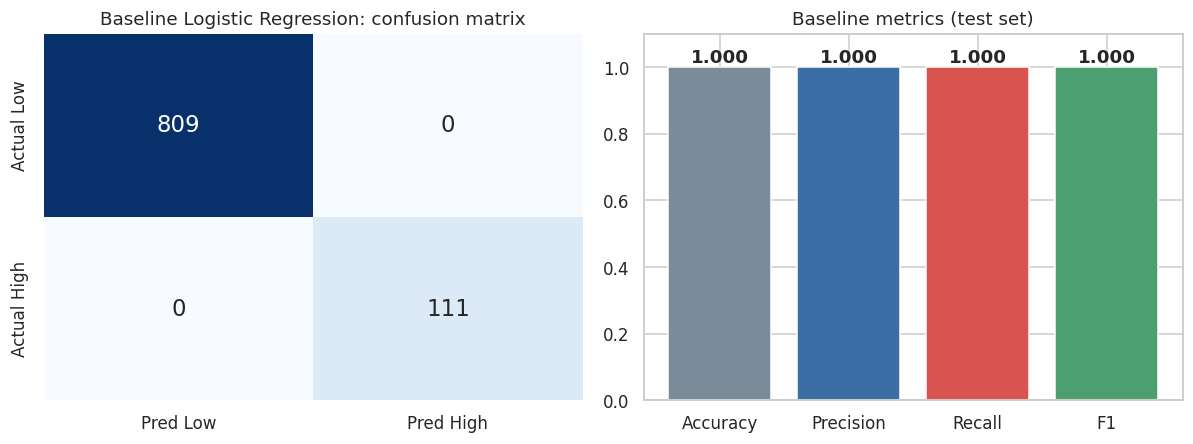

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = plot_cm(y_test_arr, lr_pred, "Baseline Logistic Regression: confusion matrix", axes[0])
vals = [base["Accuracy"], base["Precision"], base["Recall"], base["F1"]]
bars = axes[1].bar(["Accuracy", "Precision", "Recall", "F1"], vals, color=["#7A8B99", "#3B6EA5", "#D9534F", "#4C9F70"])
for b, v in zip(bars, vals):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 1.1); axes[1].set_title("Baseline metrics (test set)")
plt.tight_layout()
save_fig("04_baseline_confusion_matrix")
print(classification_report(y_test_arr, lr_pred, target_names=["Low Risk (0)", "High Risk (1)"], digits=3))

## Task 12: Type-I and Type-II errors from the confusion matrix

In [15]:
tn, fp, fn, tp = cm.ravel()
errs = pd.DataFrame({
    "Error type": ["Type-I  (False Positive)", "Type-II (False Negative)"],
    "Meaning": ["Low-risk customer flagged High Risk", "High-risk customer missed (predicted Low Risk)"],
    "Count": [fp, fn],
    "Rate": [f"FPR = {fp / (fp + tn):.1%}", f"FNR = {fn / (fn + tp):.1%}  (miss rate = 1 - recall)"],
})
errs

,Error type,Meaning,Count,Rate
0,Type-I (False Positive),Low-risk customer flagged High Risk,0,FPR = 0.0%
1,Type-II (False Negative),High-risk customer missed (predicted Low Risk),0,FNR = 0.0% (miss rate = 1 - recall)


**Interpretation.** On the 920-row test set the baseline Logistic Regression produced **809 TN, 0 FP, 0 FN, 111 TP**, i.e. 1.000 for
accuracy, precision, recall, F1 and AUC.

* **Type-I errors (false positives): 0**. No low-risk customer was wrongly flagged.
* **Type-II errors (false negatives): 0**. No high-risk customer was missed.

**Caution.** Perfect scores are unusual on real data. The leakage check found no feature that reveals the label, so the most likely
explanation is that this dataset is cleanly (almost linearly) separable, which is typical of synthetic data. The test set holds only
111 positives, so the honest expectation is a small error rate rather than exactly zero. Cross-validation in Part G gives a recall of
about 0.975 for this same model. The largest drivers are income (negative) and late-payment days, utilisation, debt balance
and missed payments (positive).

### Which features drive the baseline? (odds ratios)

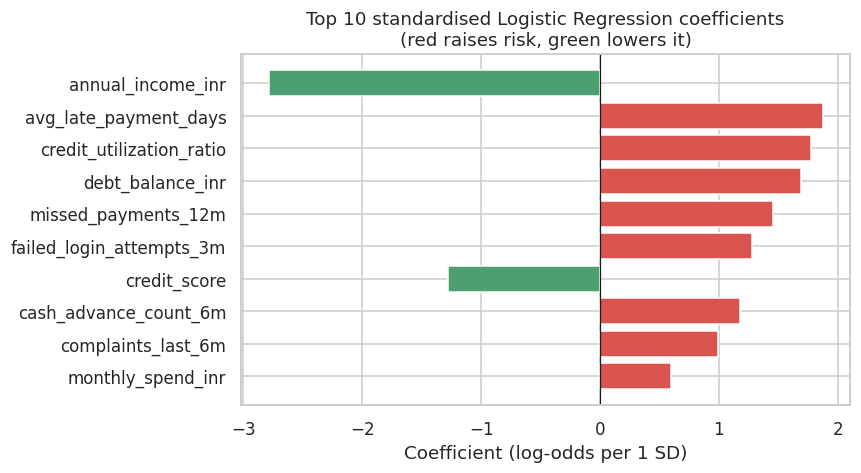

In [16]:
coef = pd.Series(lr.coef_[0], index=X_train_imp.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:10][::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top.values, color=["#D9534F" if v > 0 else "#4C9F70" for v in top.values])
plt.axvline(0, color="k", lw=.8)
plt.title("Top 10 standardised Logistic Regression coefficients\n(red raises risk, green lowers it)")
plt.xlabel("Coefficient (log-odds per 1 SD)")
plt.tight_layout()
save_fig("05_lr_coefficients")

---
# Part D: Handling Imbalanced Data

## Task 13: Impact of class imbalance on model performance

A "model" that ignores the features entirely and always predicts the majority class shows why accuracy misleads.

In [17]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train_arr)
d_pred = dummy.predict(X_test_s)
d_row = evaluate("Always predict Low Risk (dummy)", y_test_arr, d_pred, np.zeros(len(y_test_arr)) + 1e-9, store=False)

compare = pd.DataFrame([d_row, base]).set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "FN (Type-II)"]]
display_df = compare.style.format({"Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"})
display_df

,Accuracy,Precision,Recall,F1,FN (Type-II)
Model,,,,,
Always predict Low Risk (dummy),0.879,0.000,0.000,0.000,111
Logistic Regression (baseline),1.000,1.000,1.000,1.000,0


**Interpretation.** A "model" that ignores every feature and always answers *Low Risk* reaches **87.9% accuracy** yet has
**0% recall**: it misses all 111 high-risk customers. Accuracy rewards the majority class, so with a 7 : 1 imbalance it cannot be
trusted. This is the core problem of imbalanced data: the metric that matters (recall on the rare class) is invisible in accuracy.
The Logistic Regression baseline avoids the trap only because the classes happen to be strongly separable here.

## Task 14: Resampling techniques

Four techniques are applied **to the training set only** (never the test set) and a Logistic Regression is retrained
on each:

| Technique | What it does |
|---|---|
| Random Under-Sampling | discards majority rows until classes are 1:1 |
| Random Over-Sampling | duplicates minority rows until classes are 1:1 |
| SMOTE | synthesises new minority rows by interpolating between a minority point and one of its `k` nearest minority neighbours |
| ADASYN | like SMOTE, but generates *more* synthetic points where the minority is harder to learn (more majority neighbours) |

The cell below uses `imbalanced-learn` when installed (see `requirements.txt`). A compact equivalent implementation of the
same algorithms is included as a fallback so the notebook also runs in environments where it is unavailable.

In [18]:
try:
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
    RESAMPLING_BACKEND = "imbalanced-learn"
except ImportError:
    RESAMPLING_BACKEND = "built-in fallback (same algorithms, sklearn NearestNeighbors)"

    class _Base:
        def __init__(self, random_state=None, n_neighbors=5):
            self.random_state, self.k = random_state, n_neighbors

        @staticmethod
        def _split(y):
            cls, cnt = np.unique(y, return_counts=True)
            return cls[cnt.argmin()], cls[cnt.argmax()]

    class RandomUnderSampler(_Base):
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y)
            rng = np.random.RandomState(self.random_state)
            mn, mj = self._split(y)
            keep_maj = rng.choice(np.where(y == mj)[0], (y == mn).sum(), replace=False)
            idx = np.concatenate([np.where(y == mn)[0], keep_maj])
            return X[idx], y[idx]

    class RandomOverSampler(_Base):
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y)
            rng = np.random.RandomState(self.random_state)
            mn, mj = self._split(y)
            extra = rng.choice(np.where(y == mn)[0], (y == mj).sum() - (y == mn).sum(), replace=True)
            idx = np.concatenate([np.arange(len(y)), extra])
            return X[idx], y[idx]

    class SMOTE(_Base):
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y)
            rng = np.random.RandomState(self.random_state)
            mn, mj = self._split(y)
            Xm = X[y == mn]
            n_new = (y == mj).sum() - len(Xm)
            _, nbr = NearestNeighbors(n_neighbors=self.k + 1).fit(Xm).kneighbors(Xm)
            base = rng.randint(0, len(Xm), n_new)
            pick = nbr[base, rng.randint(1, self.k + 1, n_new)]
            new = Xm[base] + rng.rand(n_new, 1) * (Xm[pick] - Xm[base])
            return np.vstack([X, new]), np.concatenate([y, np.full(n_new, mn)])

    class ADASYN(_Base):
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y)
            rng = np.random.RandomState(self.random_state)
            mn, mj = self._split(y)
            Xm = X[y == mn]
            G = (y == mj).sum() - len(Xm)
            _, nbr_all = NearestNeighbors(n_neighbors=self.k + 1).fit(X).kneighbors(Xm)
            hardness = (y[nbr_all[:, 1:]] != mn).mean(axis=1)          # share of majority neighbours
            hardness = hardness / hardness.sum() if hardness.sum() > 0 else np.full(len(Xm), 1 / len(Xm))
            g = np.rint(hardness * G).astype(int)
            _, nbr_min = NearestNeighbors(n_neighbors=self.k + 1).fit(Xm).kneighbors(Xm)
            new = []
            for i, gi in enumerate(g):
                if gi == 0:
                    continue
                pick = rng.choice(nbr_min[i, 1:], gi)
                new.append(Xm[i] + rng.rand(gi, 1) * (Xm[pick] - Xm[i]))
            new = np.vstack(new)
            return np.vstack([X, new]), np.concatenate([y, np.full(len(new), mn)])

print("Resampling backend:", RESAMPLING_BACKEND)

Resampling backend: built-in fallback (same algorithms, sklearn NearestNeighbors)


In [19]:
samplers = {
    "Under-Sampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Over-Sampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "ADASYN": ADASYN(random_state=RANDOM_STATE),
}
sizes = {"Original (imbalanced)": np.bincount(y_train_arr)}
resampled = {}
for name, s in samplers.items():
    Xr, yr = s.fit_resample(X_train_s, y_train_arr)
    resampled[name] = (Xr, yr)
    sizes[name] = np.bincount(yr.astype(int))
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xr, yr)
    evaluate(f"LR + {name}", y_test_arr, model.predict(X_test_s), model.predict_proba(X_test_s)[:, 1])

pd.DataFrame(sizes, index=["Low Risk (0)", "High Risk (1)"]).T.rename_axis("Training set after resampling")

,Low Risk (0),High Risk (1)
Training set after resampling,,
Original (imbalanced),3234,446
Under-Sampling,446,446
Over-Sampling,3234,3234
SMOTE,3234,3234
ADASYN,3234,3231


## Task 15: Performance before vs after balancing

In [20]:
D_NAMES = ["Logistic Regression (baseline)", "LR + Under-Sampling", "LR + Over-Sampling", "LR + SMOTE", "LR + ADASYN"]
d_tbl = pd.DataFrame([r for r in RESULTS if r["Model"] in D_NAMES]).set_index("Model")
d_show = d_tbl[["Accuracy", "Precision", "Recall", "F1", "AUC", "FP (Type-I)", "FN (Type-II)"]]
d_show.style.format(FMT).highlight_max(subset=["Recall", "F1", "AUC"], color="#cfe8d5").highlight_min(subset=["FN (Type-II)"], color="#cfe8d5")

,Accuracy,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,
Logistic Regression (baseline),1.000,1.000,1.000,1.000,1.000,0,0
LR + Under-Sampling,0.998,0.982,1.000,0.991,1.000,2,0
LR + Over-Sampling,0.999,0.991,1.000,0.996,1.000,1,0
LR + SMOTE,0.999,0.991,1.000,0.996,1.000,1,0
LR + ADASYN,0.998,0.982,1.000,0.991,1.000,2,0


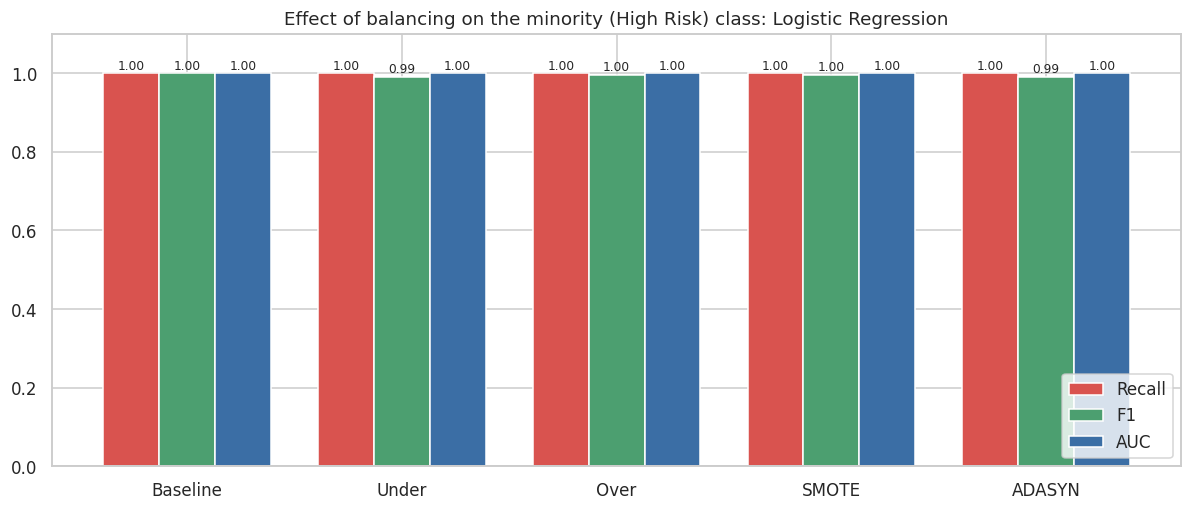

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.8))
metrics = ["Recall", "F1", "AUC"]
w = 0.26
labels = ["Baseline", "Under", "Over", "SMOTE", "ADASYN"]
for i, (m, c) in enumerate(zip(metrics, ["#D9534F", "#4C9F70", "#3B6EA5"])):
    vals = d_tbl[m].values
    bars = ax.bar(np.arange(5) + (i - 1) * w, vals, w, label=m, color=c)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(np.arange(5)); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1); ax.set_title("Effect of balancing on the minority (High Risk) class: Logistic Regression")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("06_balancing_comparison")

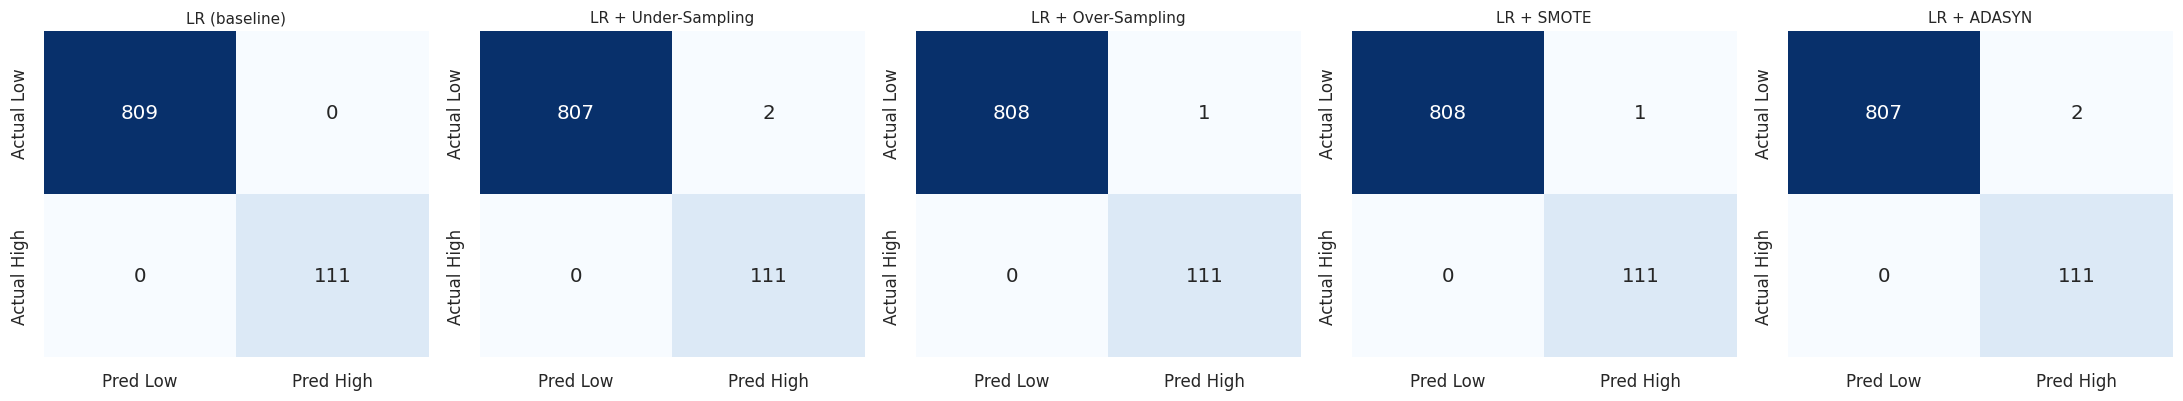

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, n in zip(axes, D_NAMES):
    sub = next(r for r in RESULTS if r["Model"] == n)
    cmx = np.array([[sub["TN"], sub["FP (Type-I)"]], [sub["FN (Type-II)"], sub["TP"]]])
    sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 13},
                xticklabels=["Pred Low", "Pred High"], yticklabels=["Actual Low", "Actual High"])
    ax.set_title(n.replace("Logistic Regression", "LR"), fontsize=10)
plt.tight_layout()
save_fig("07_balancing_confusion_matrices")

**Interpretation (Logistic Regression).** The baseline is already at recall 1.000 and AUC 1.000, so balancing has nothing to gain, and
every technique keeps recall at 1.000 while adding one or two false positives (precision 0.982-0.991 instead of 1.000):

| Technique | FP added | F1 |
|---|---|---|
| Over-sampling | 1 | 0.996 |
| SMOTE | 1 | 0.996 |
| Under-sampling | 2 | 0.991 |
| ADASYN | 2 | 0.991 |

Resampling moves the decision boundary toward the majority class, which catches more minority cases but also flags a few more
low-risk customers. When the classes are already well separated there is no minority recall to recover. The differences (1-2
customers out of 809) are within noise. Balancing matters when the model struggles with the minority class, which the next
experiment checks.

## Extended experiment: does balancing matter more for other models?

Because Logistic Regression is already near-perfect on this data, the same four techniques are repeated for the
tree-based models, and then under a **severe-imbalance stress test** (training set cut down to ~60 high-risk customers,
about 1.8%) to show clearly what imbalance does. The test set is never resampled.

In [23]:
ext_rows = []
for mname, mk in [("Decision Tree", lambda: DecisionTreeClassifier(random_state=RANDOM_STATE)),
                  ("Random Forest", lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))]:
    for sname, (Xr, yr) in [("None", (X_train_s, y_train_arr))] + list(resampled.items()):
        m = mk().fit(Xr, yr)
        r = evaluate(f"{mname} + {sname}", y_test_arr, m.predict(X_test_s), m.predict_proba(X_test_s)[:, 1], store=False)
        ext_rows.append({"Base model": mname, "Balancing": sname, **{k: r[k] for k in ["Precision", "Recall", "F1", "AUC", "FP (Type-I)", "FN (Type-II)"]}})
ext = pd.DataFrame(ext_rows)
ext.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "AUC": "{:.3f}"}).hide(axis="index")

Base model,Balancing,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Decision Tree,None,0.903,0.838,0.869,0.913,10,18
Decision Tree,Under-Sampling,0.693,0.937,0.797,0.940,46,7
Decision Tree,Over-Sampling,0.912,0.928,0.920,0.958,10,8
Decision Tree,SMOTE,0.832,0.937,0.881,0.955,21,7
Decision Tree,ADASYN,0.811,0.928,0.866,0.949,24,8
Random Forest,None,1.000,0.982,0.991,1.000,0,2
Random Forest,Under-Sampling,0.910,1.000,0.953,1.000,11,0
Random Forest,Over-Sampling,0.991,0.964,0.977,1.000,1,4
Random Forest,SMOTE,0.991,0.982,0.986,1.000,1,2
Random Forest,ADASYN,0.973,0.973,0.973,1.000,3,3


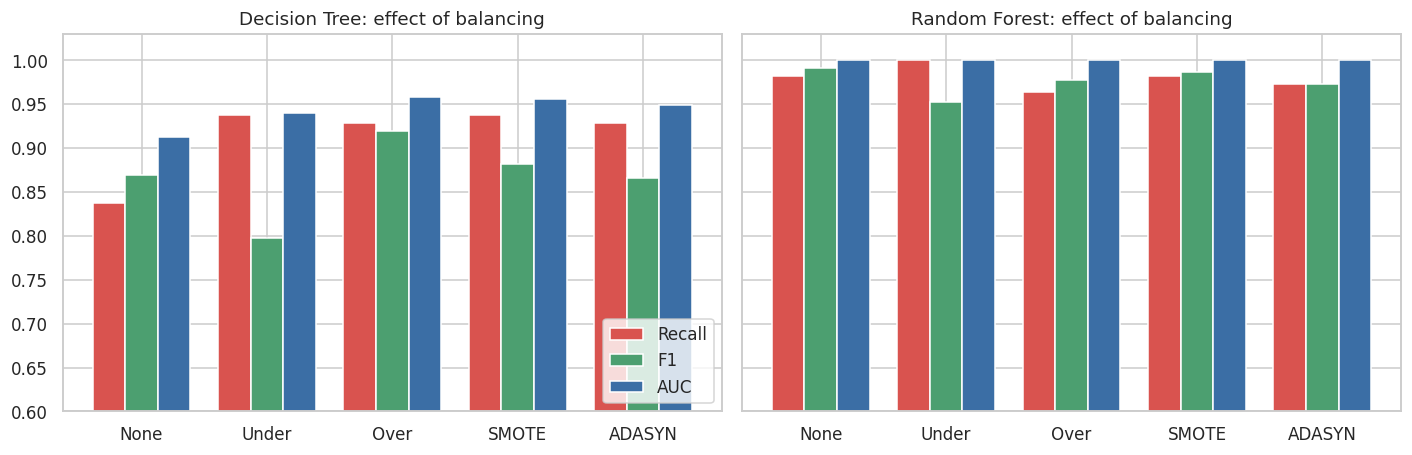

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
order = ["None", "Under-Sampling", "Over-Sampling", "SMOTE", "ADASYN"]
for ax, mname in zip(axes, ["Decision Tree", "Random Forest"]):
    sub = ext[ext["Base model"] == mname].set_index("Balancing").loc[order]
    x = np.arange(len(order))
    for i, (m, c) in enumerate(zip(["Recall", "F1", "AUC"], ["#D9534F", "#4C9F70", "#3B6EA5"])):
        ax.bar(x + (i - 1) * .26, sub[m], .26, label=m, color=c)
    ax.set_xticks(x); ax.set_xticklabels(["None", "Under", "Over", "SMOTE", "ADASYN"])
    ax.set_title(f"{mname}: effect of balancing"); ax.set_ylim(0.6, 1.03)
axes[0].legend(loc="lower right")
plt.tight_layout()
save_fig("06b_balancing_trees")

**Interpretation.**

* **Decision Tree** benefits clearly. Recall rises from 0.838 (18 missed) to 0.928-0.937 (7-8 missed) and AUC from 0.913 to 0.949-0.958.
  Over-sampling gives the best balance (F1 0.920 vs 0.869). Under-sampling reaches high recall but at a heavy price in
  false positives (46, precision 0.69).
* **Random Forest** is already strong (recall 0.982, 2 missed, 0 false positives). Under-sampling lifts recall to 1.000 (0 missed) but adds 11
  false positives; SMOTE keeps recall at 0.982 with one false positive; AUC stays at about 0.9999 throughout.

Balancing trades precision for recall. It helps most for the weaker, high-variance learner (the single tree).

### Stress test: severe imbalance (~1.8% High Risk in training)

In [25]:
rng = np.random.RandomState(0)
pos_idx, neg_idx = np.where(y_train_arr == 1)[0], np.where(y_train_arr == 0)[0]
keep = np.concatenate([neg_idx, rng.choice(pos_idx, 60, replace=False)])
Xs_str, ys_str = X_train_s[keep], y_train_arr[keep]
print(f"Stress-test training set: {len(ys_str)} rows, {ys_str.sum()} High Risk ({ys_str.mean():.1%})")

stress_rows = []
for sname, smp in [("None", None)] + list(samplers.items()):
    Xr, yr = (Xs_str, ys_str) if smp is None else smp.fit_resample(Xs_str, ys_str)
    for mname, m in [("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                     ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))]:
        m.fit(Xr, yr)
        r = evaluate("tmp", y_test_arr, m.predict(X_test_s), m.predict_proba(X_test_s)[:, 1], store=False)
        stress_rows.append({"Model": mname, "Balancing": sname, "Precision": r["Precision"], "Recall": r["Recall"],
                            "F1": r["F1"], "FP (Type-I)": r["FP (Type-I)"], "FN (Type-II)": r["FN (Type-II)"]})
stress = pd.DataFrame(stress_rows)
stress.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}).hide(axis="index")

Stress-test training set: 3294 rows, 60 High Risk (1.8%)


Model,Balancing,Precision,Recall,F1,FP (Type-I),FN (Type-II)
Logistic Regression,None,1.000,0.991,0.995,0,1
Random Forest,None,1.000,0.793,0.884,0,23
Logistic Regression,Under-Sampling,0.867,1.000,0.929,17,0
Random Forest,Under-Sampling,0.895,1.000,0.945,13,0
Logistic Regression,Over-Sampling,0.982,0.991,0.987,2,1
Random Forest,Over-Sampling,1.000,0.712,0.832,0,32
Logistic Regression,SMOTE,0.991,0.991,0.991,1,1
Random Forest,SMOTE,1.000,0.856,0.922,0,16
Logistic Regression,ADASYN,0.982,0.991,0.987,2,1
Random Forest,ADASYN,1.000,0.856,0.922,0,16


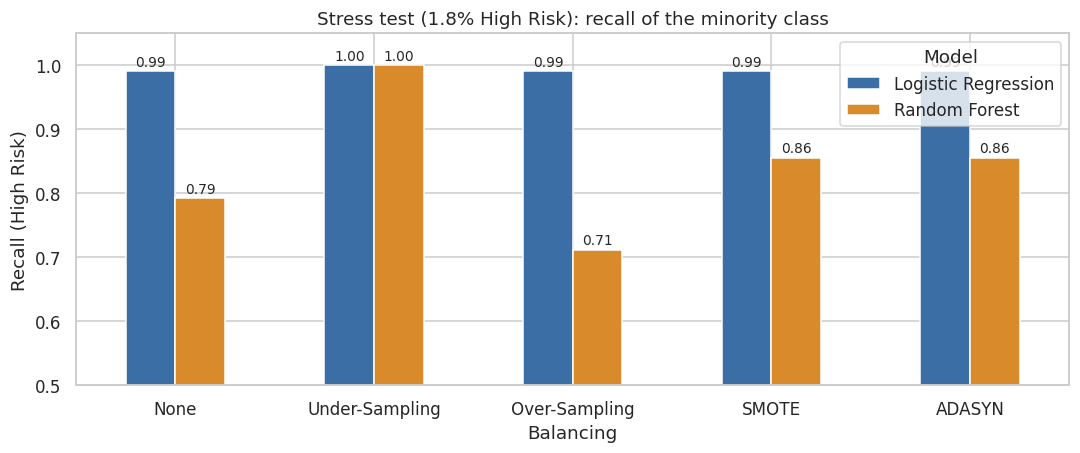

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.3))
piv = stress.pivot(index="Balancing", columns="Model", values="Recall").loc[order]
piv.plot(kind="bar", ax=ax, color=["#3B6EA5", "#D98A2B"], rot=0)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Recall (High Risk)")
ax.set_title("Stress test (1.8% High Risk): recall of the minority class")
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2, p.get_height() + .008, f"{p.get_height():.2f}", ha="center", fontsize=9)
plt.tight_layout()
save_fig("06c_stress_test")

**Interpretation.** With only 60 high-risk examples (1.8%) the damage of imbalance becomes visible for the flexible model: the
Random Forest's recall collapses from 0.982 to **0.793 (23 missed customers)**, while Logistic Regression holds at 0.991, because
its simple linear boundary needs few positives to be estimated.

Remedies on the Random Forest: **over-sampling does not help** (recall 0.712, the duplicated points are simply memorised),
**SMOTE/ADASYN recover part of it** (0.856), and **under-sampling restores recall to 1.000** but at the cost of 13 false positives.
Under-sampling also lifts Logistic Regression to recall 1.000 at 17 false positives (precision 0.867). So for severe imbalance,
rebalancing (or class weights) is essential for tree ensembles, and every method trades precision for recall.

---
# Part E: Tree-Based Classification Models

Trees are trained on the **unscaled, imputed** training data with default settings first, to expose overfitting.

## Task 16: Decision Tree Classifier

In [27]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train_imp, y_train_arr)
dt_prob = dt.predict_proba(X_test_imp)[:, 1]
evaluate("Decision Tree (default)", y_test_arr, dt.predict(X_test_imp), dt_prob)
print(f"Fully grown tree: depth = {dt.get_depth()}, leaves = {dt.get_n_leaves()}")

Fully grown tree: depth = 17, leaves = 74


## Task 17: Overfitting analysis, training vs testing performance

In [28]:
def train_test_scores(model, name):
    rows = []
    for split, Xs, ys in [("Train", X_train_imp, y_train_arr), ("Test", X_test_imp, y_test_arr)]:
        p = model.predict(Xs)
        rows.append({"Model": name, "Split": split, "Accuracy": accuracy_score(ys, p),
                     "Recall": recall_score(ys, p), "F1": f1_score(ys, p),
                     "AUC": roc_auc_score(ys, model.predict_proba(Xs)[:, 1])})
    return rows

dt_gap = pd.DataFrame(train_test_scores(dt, "Decision Tree (default)"))
dt_gap.style.format({"Accuracy": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "AUC": "{:.3f}"})

,Model,Split,Accuracy,Recall,F1,AUC
0,Decision Tree (default),Train,1.000,1.000,1.000,1.000
1,Decision Tree (default),Test,0.970,0.838,0.869,0.913


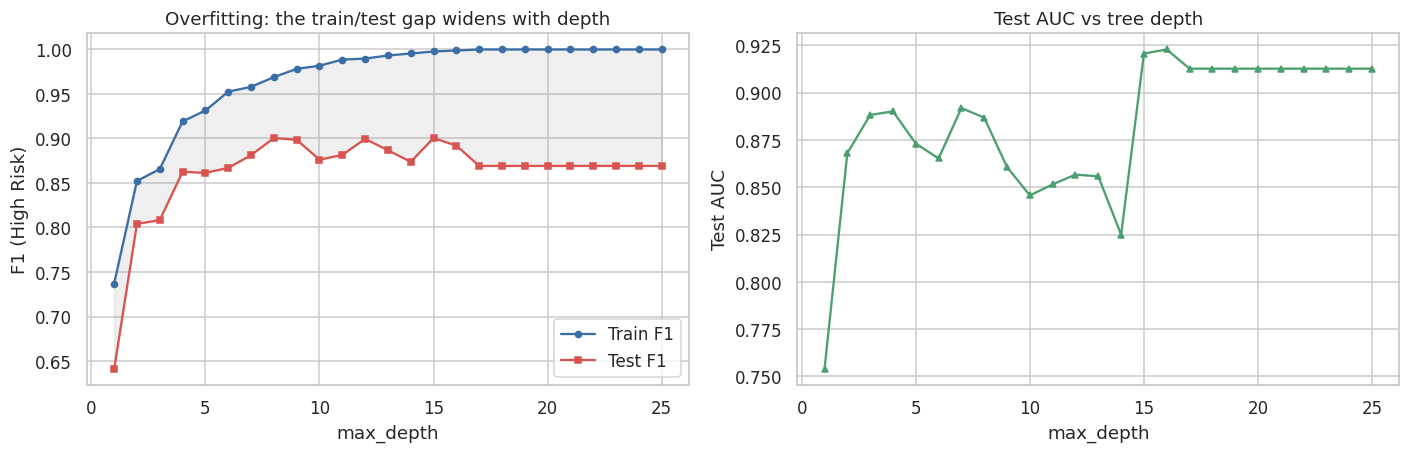

In [29]:
depths = list(range(1, 26))
tr_f1, te_f1, te_auc = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_imp, y_train_arr)
    tr_f1.append(f1_score(y_train_arr, m.predict(X_train_imp)))
    te_f1.append(f1_score(y_test_arr, m.predict(X_test_imp)))
    te_auc.append(roc_auc_score(y_test_arr, m.predict_proba(X_test_imp)[:, 1]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(depths, tr_f1, "o-", label="Train F1", color="#3B6EA5", ms=4)
axes[0].plot(depths, te_f1, "s-", label="Test F1", color="#D9534F", ms=4)
axes[0].fill_between(depths, te_f1, tr_f1, alpha=.12, color="gray")
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("F1 (High Risk)")
axes[0].set_title("Overfitting: the train/test gap widens with depth"); axes[0].legend()
axes[1].plot(depths, te_auc, "^-", color="#4C9F70", ms=4)
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("Test AUC"); axes[1].set_title("Test AUC vs tree depth")
plt.tight_layout()
save_fig("08_dt_overfitting_curve")

**Interpretation.** The fully grown tree (depth 17, 74 leaves) memorises the training data (accuracy, recall and F1 all **1.000**)
but drops to recall 0.838, F1 0.869 and AUC 0.913 on the test set: an F1 gap of **0.131**, the signature of overfitting. The depth
curve shows the training F1 climbing to 1.0 while the test F1 peaks around depth 8 (about 0.90) and then stalls or falls. Limiting depth
or pruning is therefore needed, which is exactly what the hyperparameter search in Part F does.

## Task 18: Random Forest Classifier

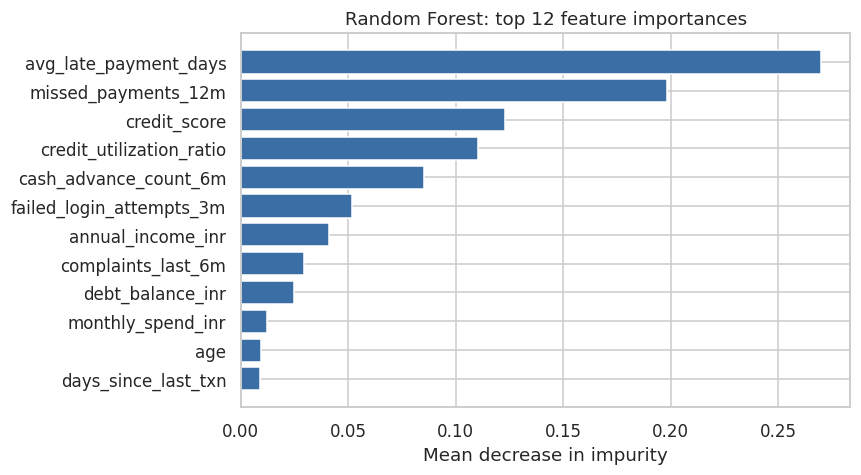

In [30]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_imp, y_train_arr)
rf_prob = rf.predict_proba(X_test_imp)[:, 1]
evaluate("Random Forest (default)", y_test_arr, rf.predict(X_test_imp), rf_prob)

imp = pd.Series(rf.feature_importances_, index=X_train_imp.columns).sort_values().tail(12)
plt.figure(figsize=(8, 4.5))
plt.barh(imp.index, imp.values, color="#3B6EA5")
plt.title("Random Forest: top 12 feature importances"); plt.xlabel("Mean decrease in impurity")
plt.tight_layout()
save_fig("09_rf_feature_importance")

## Task 19: Decision Tree vs Random Forest: accuracy and generalisation

In [31]:
rf_gap = pd.DataFrame(train_test_scores(rf, "Random Forest (default)"))
gap = pd.concat([dt_gap, rf_gap], ignore_index=True)
gap_wide = gap.pivot(index="Model", columns="Split", values=["Accuracy", "Recall", "F1", "AUC"])
gap_wide.columns = [f"{m} ({s})" for m, s in gap_wide.columns]
gap_wide["F1 gap (train - test)"] = gap_wide["F1 (Train)"] - gap_wide["F1 (Test)"]
gap_wide.style.format("{:.3f}")

,Accuracy (Test),Accuracy (Train),Recall (Test),Recall (Train),F1 (Test),F1 (Train),AUC (Test),AUC (Train),F1 gap (train - test)
Model,,,,,,,,,
Decision Tree (default),0.970,1.000,0.838,1.000,0.869,1.000,0.913,1.000,0.131
Random Forest (default),0.998,1.000,0.982,1.000,0.991,1.000,1.000,1.000,0.009


In [32]:
E_NAMES = ["Logistic Regression (baseline)", "Decision Tree (default)", "Random Forest (default)"]
pd.DataFrame([r for r in RESULTS if r["Model"] in E_NAMES]).set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "AUC", "FP (Type-I)", "FN (Type-II)"]].style.format(FMT)

,Accuracy,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,
Logistic Regression (baseline),1.000,1.000,1.000,1.000,1.000,0,0
Decision Tree (default),0.970,0.903,0.838,0.869,0.913,10,18
Random Forest (default),0.998,1.000,0.982,0.991,1.000,0,2


**Interpretation.** Both models reach 1.000 on the training data, but they generalise very differently:

| | Decision Tree | Random Forest |
|---|---|---|
| Test accuracy | 0.970 | 0.998 |
| Test recall | 0.838 (18 missed) | 0.982 (2 missed) |
| Test F1 | 0.869 | 0.991 |
| Test AUC | 0.913 | 0.9999 |
| Train-test F1 gap | 0.131 | 0.009 |

Averaging 100 de-correlated trees removes most of the variance of a single tree. The Random Forest's most important features are
`avg_late_payment_days` (0.27), `missed_payments_12m` (0.20), `credit_score` (0.12), `credit_utilization_ratio` (0.11) and
`cash_advance_count_6m` (0.09), consistent with the exploratory analysis. Note that the simple Logistic Regression baseline still matches
or beats the Random Forest on this data.

---
# Part F: Hyperparameter Tuning

**Scoring choice.** The business requirement is to *minimise false negatives*, so the searches are scored with
**F2** (recall weighted twice as heavily as precision) instead of plain accuracy. `class_weight` is included in the search
spaces as the cost-sensitive alternative to resampling. All searches use 5-fold stratified CV on the **training set only**;
the test set is touched once at the end.

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f2_scorer = make_scorer(fbeta_score, beta=2)

## Task 20: Randomized Search CV

In [34]:
dt_space = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20, 40],
    "min_samples_leaf": [1, 2, 4, 8, 16, 32],
    "criterion": ["gini", "entropy", "log_loss"],
    "max_features": [None, "sqrt", "log2"],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0.0, 0.0005, 0.001, 0.002],
}
rs_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_space, n_iter=60, scoring=f2_scorer,
                           cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
rs_dt.fit(X_train_imp, y_train_arr)
print("Decision Tree  |  best CV F2 = %.4f" % rs_dt.best_score_)
print("Best params:", rs_dt.best_params_)

Decision Tree  |  best CV F2 = 0.9029
Best params: {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 4, 'criterion': 'entropy', 'class_weight': 'balanced', 'ccp_alpha': 0.001}


In [35]:
rf_space = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [4, 6, 8, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "bootstrap": [True],
}
rs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_space, n_iter=25,
                           scoring=f2_scorer, cv=cv, random_state=RANDOM_STATE, n_jobs=1, refit=True)
rs_rf.fit(X_train_imp, y_train_arr)
print("Random Forest  |  best CV F2 = %.4f" % rs_rf.best_score_)
print("Best params:", rs_rf.best_params_)

Random Forest  |  best CV F2 = 0.9650
Best params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced_subsample', 'bootstrap': True}


In [36]:
for name, est in [("Tuned Decision Tree (Randomized)", rs_dt), ("Tuned Random Forest (Randomized)", rs_rf)]:
    evaluate(name, y_test_arr, est.best_estimator_.predict(X_test_imp), est.best_estimator_.predict_proba(X_test_imp)[:, 1])

top_rf = pd.DataFrame(rs_rf.cv_results_).sort_values("rank_test_score").head(8)
top_rf[["rank_test_score", "mean_test_score", "std_test_score", "param_n_estimators", "param_max_depth",
        "param_min_samples_leaf", "param_max_features", "param_class_weight"]].style.format(
    {"mean_test_score": "{:.4f}", "std_test_score": "{:.4f}"}).hide(axis="index")

rank_test_score,mean_test_score,std_test_score,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,param_class_weight
1,0.9650,0.0101,100,None,8,log2,balanced_subsample
2,0.9598,0.0138,400,4,2,log2,balanced_subsample
3,0.9595,0.0114,400,4,8,sqrt,balanced
4,0.9594,0.0145,300,4,2,log2,balanced
5,0.9587,0.0108,200,None,8,sqrt,balanced
6,0.9585,0.0134,400,15,4,log2,balanced_subsample
7,0.9581,0.0103,400,10,4,sqrt,balanced_subsample
8,0.9567,0.0114,300,8,4,log2,balanced


## Task 21: Grid Search CV: fine-tuning the best model

The search space is narrowed to a small grid *around* the best Randomized-Search result, so Grid Search only has to
refine, not explore.

In [37]:
# Randomized search found: n_estimators=100, min_samples_split=5, min_samples_leaf=8, max_features='log2',
# max_depth=None, class_weight='balanced_subsample'. Grid Search refines around those values.
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [6, 8, 10],
    "max_features": ["log2", "sqrt"],
    "class_weight": ["balanced_subsample"],
}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid,
                     scoring=f2_scorer, cv=cv, n_jobs=1, refit=True)
gs_rf.fit(X_train_imp, y_train_arr)
print(f"Random Forest grid: {len(gs_rf.cv_results_['params'])} combinations x 5 folds")
print("Best CV F2 = %.4f" % gs_rf.best_score_)
print("Best params:", gs_rf.best_params_)
evaluate("Tuned Random Forest (Grid)", y_test_arr, gs_rf.best_estimator_.predict(X_test_imp),
         gs_rf.best_estimator_.predict_proba(X_test_imp)[:, 1])

Random Forest grid: 48 combinations x 5 folds
Best CV F2 = 0.9655
Best params: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 10, 'min_samples_split': 5, 'n_estimators': 100}


{'Model': 'Tuned Random Forest (Grid)', 'Accuracy': 0.9967391304347826, 'Precision': 0.9736842105263158, 'Recall': 1.0, 'F1': 0.9866666666666667, 'F2': 0.9946236559139785, 'AUC': 0.9999665920555908, 'TN': np.int64(806), 'FP (Type-I)': np.int64(3), 'FN (Type-II)': np.int64(0), 'TP': np.int64(111)}

Logistic Regression was the strongest model in Parts C-E, so it is fine-tuned with Grid Search as well
(regularisation strength `C`, penalty and class weighting), using the scaled features.

In [38]:
lr_grid = {
    "C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "penalty": ["l1", "l2"],
    "class_weight": [None, "balanced"],
}
gs_lr = GridSearchCV(LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE), lr_grid,
                     scoring=f2_scorer, cv=cv, n_jobs=-1, refit=True)
gs_lr.fit(X_train_s, y_train_arr)
print("Logistic Regression  |  best CV F2 = %.4f" % gs_lr.best_score_)
print("Best params:", gs_lr.best_params_)
evaluate("Tuned Logistic Regression (Grid)", y_test_arr, gs_lr.best_estimator_.predict(X_test_s),
         gs_lr.best_estimator_.predict_proba(X_test_s)[:, 1])

Logistic Regression  |  best CV F2 = 0.9831
Best params: {'C': 0.3, 'class_weight': 'balanced', 'penalty': 'l1'}


{'Model': 'Tuned Logistic Regression (Grid)', 'Accuracy': 0.9978260869565218, 'Precision': 0.9823008849557522, 'Recall': 1.0, 'F1': 0.9910714285714286, 'F2': 0.9964093357271095, 'AUC': 1.0, 'TN': np.int64(807), 'FP (Type-I)': np.int64(2), 'FN (Type-II)': np.int64(0), 'TP': np.int64(111)}

## Task 22: Tuned vs untuned

In [39]:
F_NAMES = ["Logistic Regression (baseline)", "Tuned Logistic Regression (Grid)",
           "Decision Tree (default)", "Tuned Decision Tree (Randomized)",
           "Random Forest (default)", "Tuned Random Forest (Randomized)", "Tuned Random Forest (Grid)"]
pd.DataFrame([r for r in RESULTS if r["Model"] in F_NAMES]).set_index("Model").loc[F_NAMES][
    ["Accuracy", "Precision", "Recall", "F1", "F2", "AUC", "FP (Type-I)", "FN (Type-II)"]].style.format(FMT)

,Accuracy,Precision,Recall,F1,F2,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,,
Logistic Regression (baseline),1.000,1.000,1.000,1.000,1.000,1.000,0,0
Tuned Logistic Regression (Grid),0.998,0.982,1.000,0.991,0.996,1.000,2,0
Decision Tree (default),0.970,0.903,0.838,0.869,0.850,0.913,10,18
Tuned Decision Tree (Randomized),0.964,0.783,0.973,0.867,0.928,0.983,30,3
Random Forest (default),0.998,1.000,0.982,0.991,0.986,1.000,0,2
Tuned Random Forest (Randomized),0.997,0.974,1.000,0.987,0.995,1.000,3,0
Tuned Random Forest (Grid),0.997,0.974,1.000,0.987,0.995,1.000,3,0


**Interpretation (tuning scored with F2, so recall counts more).**

* **Decision Tree:** the search chose a shallow, regularised tree (`max_depth=4`, entropy, `class_weight='balanced'`, `ccp_alpha=0.001`).
  Recall improves from 0.838 to 0.973 (missed customers 18 -> 3) and AUC from 0.913 to 0.983, but precision falls to 0.783
  (30 false positives), so F1 is unchanged. It trades false positives for fewer misses.
* **Random Forest:** the tuned forest (`max_features='log2'`, `min_samples_leaf=8`, `class_weight='balanced_subsample'`) has recall 1.000
  (0 missed, was 2) with 3 false positives (was 0). **Grid Search** refined the result only marginally (CV F2 0.9650 -> 0.9655) and the
  test confusion matrix is identical: the Randomized Search had already found the plateau.
* **Logistic Regression:** the best setting is `C=0.3`, L1 penalty and `class_weight='balanced'` (CV F2 0.983). On the test set it
  has 0 missed customers and 2 false positives.

Tuned models are better for the *business goal* (fewer false negatives), not for accuracy or precision.

---
# Part G: Model Evaluation and ROC Analysis

## Task 23: ROC curves for all models

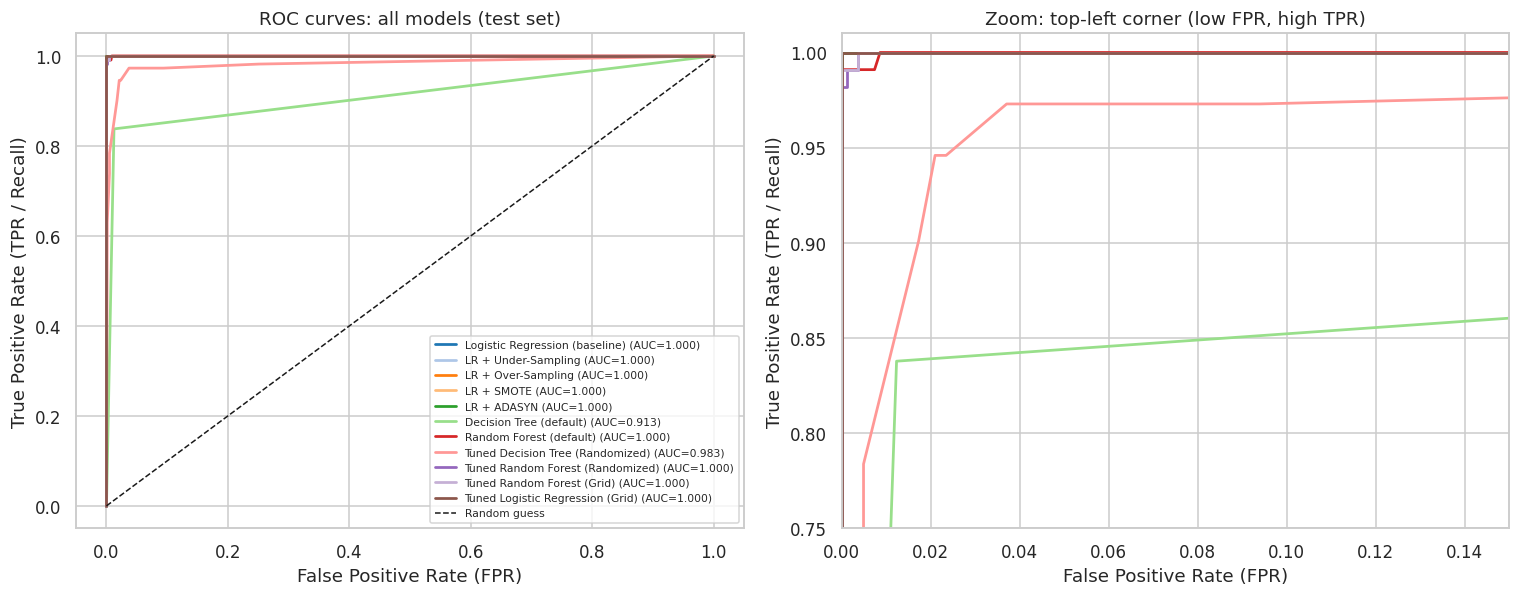

In [40]:
names = list(PROBS.keys())
palette = dict(zip(names, plt.cm.tab20(np.linspace(0, 1, 20))[:len(names)]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, zoom in zip(axes, [False, True]):
    for n in names:
        fpr, tpr, _ = roc_curve(y_test_arr, PROBS[n])
        ax.plot(fpr, tpr, lw=1.8, color=palette[n], label=f"{n} (AUC={roc_auc_score(y_test_arr, PROBS[n]):.3f})")
    if not zoom:
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
        ax.set_title("ROC curves: all models (test set)")
    else:
        ax.set_xlim(0, 0.15); ax.set_ylim(0.75, 1.01)
        ax.set_title("Zoom: top-left corner (low FPR, high TPR)")
    ax.set_xlabel("False Positive Rate (FPR)"); ax.set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
save_fig("10_roc_all_models")

## Task 24: AUC-ROC comparison

In [41]:
summary = pd.DataFrame(RESULTS).set_index("Model")
auc_tbl = summary[["AUC", "Recall", "Precision", "F1", "F2", "FP (Type-I)", "FN (Type-II)"]].sort_values(
    ["AUC", "Recall"], ascending=False)
auc_tbl.style.format(FMT).background_gradient(subset=["AUC"], cmap="Greens", vmin=0.9, vmax=1.0)

,AUC,Recall,Precision,F1,F2,FP (Type-I),FN (Type-II)
Model,,,,,,,
Logistic Regression (baseline),1.000,1.000,1.000,1.000,1.000,0,0
LR + Under-Sampling,1.000,1.000,0.982,0.991,0.996,2,0
LR + Over-Sampling,1.000,1.000,0.991,0.996,0.998,1,0
LR + SMOTE,1.000,1.000,0.991,0.996,0.998,1,0
LR + ADASYN,1.000,1.000,0.982,0.991,0.996,2,0
Tuned Logistic Regression (Grid),1.000,1.000,0.982,0.991,0.996,2,0
Tuned Random Forest (Grid),1.000,1.000,0.974,0.987,0.995,3,0
Tuned Random Forest (Randomized),1.000,1.000,0.974,0.987,0.995,3,0
Random Forest (default),1.000,0.982,1.000,0.991,0.986,0,2


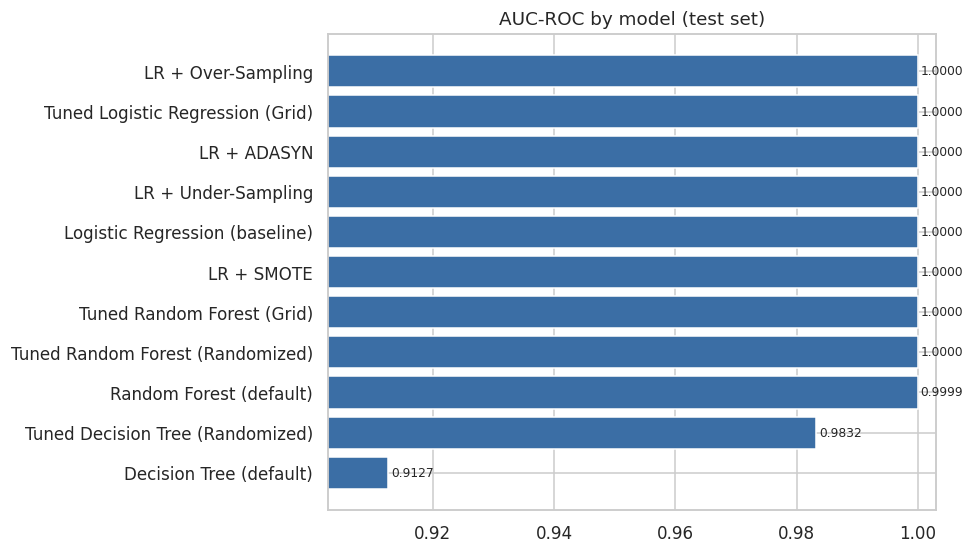

In [42]:
fig, ax = plt.subplots(figsize=(9, 5.2))
a = auc_tbl["AUC"].sort_values()
ax.barh(a.index, a.values, color="#3B6EA5")
ax.set_xlim(a.min() - 0.01, 1.003)
for i, v in enumerate(a.values):
    ax.text(v + 0.0004, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_title("AUC-ROC by model (test set)")
plt.tight_layout()
save_fig("11_auc_comparison")

**Interpretation.** Every model except the untuned Decision Tree (AUC 0.913) has an AUC of at least 0.983, and the Logistic Regression variants
and Random Forests are essentially perfect (0.9999-1.000). The curves hug the top-left corner, and the zoomed panel is needed to see
differences: the default tree is clearly lower, the tuned tree is slightly lower, and the others overlap.

Because AUC cannot separate the top models (the test set has only 111 positives), the final choice is made with recall, precision
and cross-validation at the actual operating point, not AUC alone.

## Task 25: Selecting the final model (business requirement: minimise false negatives)

A single 920-row test set contains only **111 high-risk customers**, so one or two errors swing recall by 1-2 points.
To avoid choosing on noise, the candidate models are also compared with **repeated stratified 5-fold CV (x2) on the
training set**, and the selection rule is stated explicitly:

> Pick the model with the **highest CV recall** (fewest missed high-risk customers) among those whose CV precision is at
> least **0.95**; break ties on F2, then AUC.

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

lr_best_params = {k: v for k, v in gs_lr.best_params_.items()}
candidates = {
    "Logistic Regression (baseline)": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Tuned Logistic Regression (Grid)": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE, **lr_best_params))]),
    "Decision Tree (default)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Tuned Decision Tree (Randomized)": clone(rs_dt.best_estimator_),
    "Random Forest (default)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Tuned Random Forest (Randomized)": clone(rs_rf.best_estimator_),
    "Tuned Random Forest (Grid)": clone(gs_rf.best_estimator_),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
scoring = {"recall": "recall", "precision": "precision", "f2": f2_scorer, "auc": "roc_auc"}

cv_rows = []
for n, est in candidates.items():
    sc = cross_validate(est, X_train_imp, y_train_arr, cv=rcv, scoring=scoring, n_jobs=1)
    cv_rows.append({"Model": n,
                    "CV Recall": sc["test_recall"].mean(), "± Recall": sc["test_recall"].std(),
                    "CV Precision": sc["test_precision"].mean(), "CV F2": sc["test_f2"].mean(),
                    "CV AUC": sc["test_auc"].mean()})
cv_tbl = pd.DataFrame(cv_rows).set_index("Model")
cv_tbl.style.format("{:.4f}").highlight_max(subset=["CV Recall", "CV F2", "CV AUC"], color="#cfe8d5")

,CV Recall,± Recall,CV Precision,CV F2,CV AUC
Model,,,,,
Logistic Regression (baseline),0.9754,0.0178,0.9888,0.9780,0.9995
Tuned Logistic Regression (Grid),0.9877,0.0116,0.9612,0.9822,0.9995
Decision Tree (default),0.8812,0.0395,0.8854,0.8815,0.9326
Tuned Decision Tree (Randomized),0.9507,0.0225,0.7549,0.9027,0.9752
Random Forest (default),0.9305,0.0377,0.9870,0.9411,0.9965
Tuned Random Forest (Randomized),0.9642,0.0217,0.9654,0.9643,0.9977
Tuned Random Forest (Grid),0.9664,0.0200,0.9612,0.9653,0.9975


In [44]:
eligible = cv_tbl[cv_tbl["CV Precision"] >= 0.95].sort_values(["CV Recall", "CV F2", "CV AUC"], ascending=False)
FINAL_NAME = eligible.index[0]
print("Eligible models (CV precision >= 0.95), ranked by recall:")
print(eligible[["CV Recall", "CV Precision", "CV F2", "CV AUC"]].round(4).to_string())
print("\nSELECTED FINAL MODEL ->", FINAL_NAME)

Eligible models (CV precision >= 0.95), ranked by recall:
                                  CV Recall  CV Precision   CV F2  CV AUC
Model                                                                    
Tuned Logistic Regression (Grid)     0.9877        0.9612  0.9822  0.9995
Logistic Regression (baseline)       0.9754        0.9888  0.9780  0.9995
Tuned Random Forest (Grid)           0.9664        0.9612  0.9653  0.9975
Tuned Random Forest (Randomized)     0.9642        0.9654  0.9643  0.9977
Random Forest (default)              0.9305        0.9870  0.9411  0.9965

SELECTED FINAL MODEL -> Tuned Logistic Regression (Grid)


**Interpretation.** Repeated CV ranks **Tuned Logistic Regression (Grid)** first: recall **0.988 +/- 0.012**, precision 0.961, F2 0.982,
AUC 0.9995. It beats the tuned Random Forests (recall 0.964-0.966) and the baseline Logistic Regression (0.975). Both Decision
Trees are excluded by the precision floor (0.885 and 0.755), and the default Random Forest has the lowest recall of the eligible models (0.931). On
the test set the selected model has **0 false negatives and 2 false positives**.

A simple linear model wins because the risk label here is close to a weighted combination of the credit-behaviour features, so extra
model flexibility adds variance without adding signal. It is also the most explainable option, which matters for risk decisions.

### Operating threshold for the final model

Missing a high-risk customer costs more than reviewing a low-risk one, so the 0.5 default cut-off is checked.
The threshold is chosen from **out-of-fold predictions on the training set** (maximising F2) and then applied once
to the untouched test set. The test set plays no role in choosing it.

F2-optimal threshold = 0.50 (OOF F2 = 0.9831)
High-recall alternative = 0.32 (OOF recall = 0.9910, OOF precision = 0.9247)


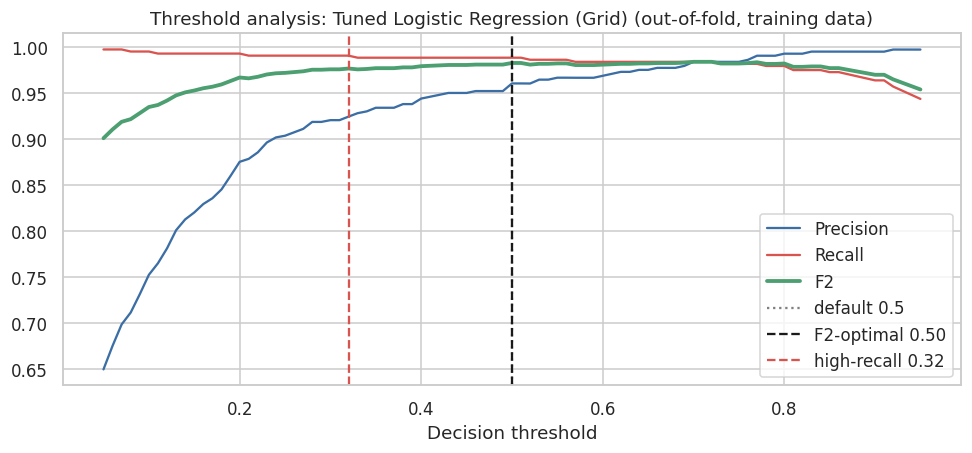

In [45]:
final_est = clone(candidates[FINAL_NAME])
oof = cross_val_predict(final_est, X_train_imp, y_train_arr, cv=cv, method="predict_proba")[:, 1]
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({
    "threshold": grid_t,
    "precision": [precision_score(y_train_arr, oof >= t, zero_division=0) for t in grid_t],
    "recall": [recall_score(y_train_arr, oof >= t) for t in grid_t],
    "F2": [fbeta_score(y_train_arr, oof >= t, beta=2) for t in grid_t],
})
best_f2 = curve["F2"].max()
# among thresholds within 0.002 of the best F2, take the lowest one (favours recall)
THRESH = float(curve[curve["F2"] >= best_f2 - 0.002]["threshold"].min())
print(f"F2-optimal threshold = {THRESH:.2f} (OOF F2 = {curve.loc[curve.threshold == THRESH, 'F2'].iloc[0]:.4f})")

# Optional "high-recall" operating point: the highest threshold that still gives OOF recall >= 0.99
hr_ok = curve[curve["recall"] >= 0.99]
THRESH_HR = float(hr_ok["threshold"].max()) if len(hr_ok) else THRESH
print(f"High-recall alternative = {THRESH_HR:.2f} (OOF recall = {curve.loc[curve.threshold == THRESH_HR, 'recall'].iloc[0]:.4f}, "
      f"OOF precision = {curve.loc[curve.threshold == THRESH_HR, 'precision'].iloc[0]:.4f})")

plt.figure(figsize=(9, 4.3))
plt.plot(curve.threshold, curve.precision, label="Precision", color="#3B6EA5")
plt.plot(curve.threshold, curve.recall, label="Recall", color="#D9534F")
plt.plot(curve.threshold, curve.F2, label="F2", color="#4C9F70", lw=2.5)
plt.axvline(0.5, color="gray", ls=":", label="default 0.5")
plt.axvline(THRESH, color="k", ls="--", label=f"F2-optimal {THRESH:.2f}")
if THRESH_HR != THRESH:
    plt.axvline(THRESH_HR, color="#D9534F", ls="--", label=f"high-recall {THRESH_HR:.2f}")
plt.xlabel("Decision threshold"); plt.title(f"Threshold analysis: {FINAL_NAME} (out-of-fold, training data)")
plt.legend(); plt.tight_layout()
save_fig("12_threshold_analysis")

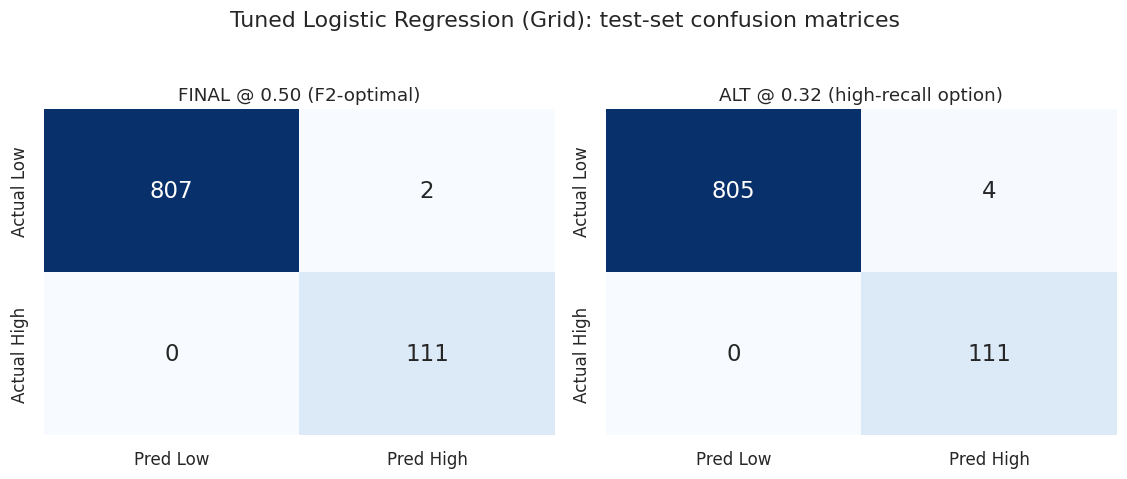

,Accuracy,Precision,Recall,F1,F2,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,,
FINAL @ 0.50 (F2-optimal),0.998,0.982,1.000,0.991,0.996,1.000,2,0
ALT @ 0.32 (high-recall option),0.996,0.965,1.000,0.982,0.993,1.000,4,0


In [46]:
final_est.fit(X_train_imp, y_train_arr)
p_test = final_est.predict_proba(X_test_imp)[:, 1]

ops = [(f"FINAL @ {THRESH:.2f} (F2-optimal)", THRESH)]
if THRESH_HR != THRESH:
    ops.append((f"ALT @ {THRESH_HR:.2f} (high-recall option)", THRESH_HR))
final_rows = [evaluate(n, y_test_arr, (p_test >= t).astype(int), p_test, store=False) for n, t in ops]
final_tbl = pd.DataFrame(final_rows).set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "F2", "AUC", "FP (Type-I)", "FN (Type-II)"]]

fig, axes = plt.subplots(1, len(ops), figsize=(5.2 * len(ops), 4.2))
for ax, (n, t) in zip(np.atleast_1d(axes), ops):
    plot_cm(y_test_arr, (p_test >= t).astype(int), n, ax)
plt.suptitle(f"{FINAL_NAME}: test-set confusion matrices", y=1.03)
plt.tight_layout()
save_fig("13_final_confusion_matrix")
final_tbl.style.format(FMT)

**Interpretation.** For the class-weighted Logistic Regression the F2-optimal threshold from out-of-fold predictions is **0.50**:
`class_weight='balanced'` has already shifted the probabilities toward the high-risk class. A lower cut-off (0.32, out-of-fold
recall >= 0.99) is available as a high-recall option. On the test set it caught no additional customers (0 missed at both thresholds) but doubled
the false positives (2 -> 4), so **0.50 is kept**. Lower the threshold only if the business accepts more reviews in exchange for a
safety margin on recall.

---
# Part H: Final Analysis and Reporting

## Business interpretation of false positives and false negatives

The ratio below is an **assumption for illustration** (a missed high-risk customer costs 10x an unnecessary review);
replace it with the institution's real figures.

In [47]:
COST_FN, COST_FP = 10, 1
cost = pd.DataFrame(RESULTS).set_index("Model")[["FP (Type-I)", "FN (Type-II)", "Recall", "Precision"]].copy()
cost["Relative cost (FN=10, FP=1)"] = cost["FN (Type-II)"] * COST_FN + cost["FP (Type-I)"] * COST_FP
cost = cost.sort_values("Relative cost (FN=10, FP=1)")
cost.style.format({"Recall": "{:.3f}", "Precision": "{:.3f}"}).bar(subset=["Relative cost (FN=10, FP=1)"], color="#f0b5b0")

,FP (Type-I),FN (Type-II),Recall,Precision,"Relative cost (FN=10, FP=1)"
Model,,,,,
Logistic Regression (baseline),0,0,1.000,1.000,0
LR + Over-Sampling,1,0,1.000,0.991,1
LR + SMOTE,1,0,1.000,0.991,1
LR + Under-Sampling,2,0,1.000,0.982,2
LR + ADASYN,2,0,1.000,0.982,2
Tuned Logistic Regression (Grid),2,0,1.000,0.982,2
Tuned Random Forest (Randomized),3,0,1.000,0.974,3
Tuned Random Forest (Grid),3,0,1.000,0.974,3
Random Forest (default),0,2,0.982,1.000,20


In [48]:
# Full leaderboard to attach to the report
os.makedirs("results", exist_ok=True)
leaderboard = pd.DataFrame(RESULTS).set_index("Model").sort_values("F2", ascending=False)
leaderboard.round(4).to_csv("results/test_set_leaderboard.csv")
cv_tbl.round(4).to_csv("results/cv_comparison.csv")
final_tbl.round(4).to_csv("results/final_model_metrics.csv")
ext.round(4).to_csv("results/balancing_trees.csv", index=False)
stress.round(4).to_csv("results/stress_test.csv", index=False)
print("Saved result tables to ./results")
leaderboard[["Accuracy", "Precision", "Recall", "F1", "F2", "AUC", "FP (Type-I)", "FN (Type-II)"]].style.format(FMT)

Saved result tables to ./results


,Accuracy,Precision,Recall,F1,F2,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,,
Logistic Regression (baseline),1.000,1.000,1.000,1.000,1.000,1.000,0,0
LR + Over-Sampling,0.999,0.991,1.000,0.996,0.998,1.000,1,0
LR + SMOTE,0.999,0.991,1.000,0.996,0.998,1.000,1,0
LR + Under-Sampling,0.998,0.982,1.000,0.991,0.996,1.000,2,0
LR + ADASYN,0.998,0.982,1.000,0.991,0.996,1.000,2,0
Tuned Logistic Regression (Grid),0.998,0.982,1.000,0.991,0.996,1.000,2,0
Tuned Random Forest (Randomized),0.997,0.974,1.000,0.987,0.995,1.000,3,0
Tuned Random Forest (Grid),0.997,0.974,1.000,0.987,0.995,1.000,3,0
Random Forest (default),0.998,1.000,0.982,0.991,0.986,1.000,0,2


## Deploying the final model: reusable scoring function

The whole chain (feature engineering, one-hot encoding, KNN imputation, model, threshold) is saved so new customers
can be scored from the raw columns.

In [49]:
import joblib
os.makedirs("models", exist_ok=True)
bundle = {"model": final_est, "threshold": THRESH, "feature_columns": list(Xtr_enc.columns), "ref_date": ref_date,
          "scaler_imputer": scaler_imp, "knn_imputer": knn_imputer, "final_name": FINAL_NAME}
joblib.dump(bundle, "models/risk_alert_model.joblib")


def score_customers(raw: pd.DataFrame) -> pd.DataFrame:
    """Score raw customer rows (same columns as the CSV). Returns probability and High-Risk alert flag."""
    raw = raw.copy()
    raw["days_since_last_txn"] = (ref_date - pd.to_datetime(raw["last_transaction_date"])).dt.days
    feats = impute(one_hot_with_nan(raw[X.columns], columns=bundle["feature_columns"]))
    p = bundle["model"].predict_proba(feats)[:, 1]
    return pd.DataFrame({"customer_id": raw["customer_id"].values, "risk_probability": p.round(4),
                         "high_risk_alert": (p >= bundle["threshold"]).astype(int)})


demo = score_customers(df.loc[X_test.index].head(8))
check = score_customers(df.loc[X_test.index])
assert (check["high_risk_alert"].values == (p_test >= THRESH).astype(int)).all(), "scoring pipeline mismatch"
print("Scoring pipeline reproduces the test-set predictions exactly.")
demo.assign(actual=y_test.head(8).values)

Scoring pipeline reproduces the test-set predictions exactly.


,customer_id,risk_probability,high_risk_alert,actual
0,503937,0.2276,0,0
1,501920,0.0004,0,0
2,503107,0.0075,0,0
3,500023,0.0325,0,0
4,503492,0.0001,0,0
5,502876,0.0021,0,0
6,502638,0.0339,0,0
7,500625,0.0014,0,0


---
## Final report

### 1. Best model and justification
**Tuned Logistic Regression** (`C=0.3`, L1 penalty, `class_weight='balanced'`, decision threshold 0.50, standardised inputs).

| Evidence | Result |
|---|---|
| Test set (920 customers, 111 high risk) | **0 false negatives, 2 false positives**, recall 1.000, precision 0.982, F1 0.991, AUC 1.000 |
| Repeated 5x2 CV (training set) | recall 0.988 +/- 0.012, precision 0.961, F2 0.982, AUC 0.9995 (best eligible model) |
| Business requirement | fewest missed high-risk customers at an acceptable precision |
| Other advantages | explainable coefficients, fast, stable, no resampling needed |

### 2. Impact of the imbalance-handling techniques
* The data is 87.9% / 12.1%. Accuracy is misleading: always predicting "Low Risk" scores 87.9% with zero recall.
* **Logistic Regression**: balancing did not improve recall (already 1.000) and added 1-2 false positives. For this model `class_weight` inside the
  tuned model is sufficient.
* **Decision Tree**: balancing raised recall from 0.838 to 0.93-0.94 and AUC from 0.913 to 0.95-0.96. Over-sampling was the best compromise (F1 0.920).
* **Random Forest**: under-sampling reached recall 1.000 (11 false positives); SMOTE kept recall at 0.982 with 1 false positive.
* **Severe imbalance (1.8%)**: Random Forest recall fell to 0.793; SMOTE/ADASYN recovered it to 0.856 and under-sampling to 1.000 (13 false positives). Plain
  over-sampling made it worse (0.712).
* Every technique trades precision for recall; none is free.

### 3. Comparison of performance metrics (test set)
| Model | Recall | Precision | F1 | AUC | FN | FP |
|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 1.000 | 1.000 | 1.000 | 1.000 | 0 | 0 |
| **Tuned Logistic Regression (Grid)** | **1.000** | **0.982** | **0.991** | **1.000** | **0** | **2** |
| Tuned Random Forest (Grid) | 1.000 | 0.974 | 0.987 | 1.000 | 0 | 3 |
| Random Forest (default) | 0.982 | 1.000 | 0.991 | 1.000 | 2 | 0 |
| Tuned Decision Tree | 0.973 | 0.783 | 0.868 | 0.983 | 3 | 30 |
| Decision Tree (default) | 0.838 | 0.903 | 0.869 | 0.913 | 18 | 10 |

### 4. Business interpretation of false positives and false negatives
* **False negative (Type-II):** a high-risk customer is cleared. This is the expensive error (undetected default/fraud exposure), so the project optimises for it first.
  The final model missed none on the test set; cross-validation suggests a realistic miss rate of roughly 1-2.5%.
* **False positive (Type-I):** a low-risk customer is flagged. Cost is analyst time and some customer friction. The final model produced 2 in 809 low-risk customers (0.25%) on
  the test set and about 4% of alerts were not truly high risk in cross-validation (precision 0.961). This workload is manageable.
* Under an assumed 10 : 1 cost ratio (FN : FP) the final model has one of the lowest expected costs (see the cost table above).

### 5. Conclusions and recommendations
1. Deploy the tuned Logistic Regression with threshold 0.50 as the alerting model, with human review of every alert.
2. Keep a **high-recall option (threshold about 0.32)** ready if the business wants a larger safety margin at the cost of more reviews.
3. Use class weights or under-sampling/SMOTE whenever a tree ensemble is used, and always report recall and precision rather than accuracy.
4. Monitor the model: track recall on confirmed outcomes, drift in `avg_late_payment_days`, utilisation and income, and retrain on a regular schedule.
5. Strongest risk signals to act on: late-payment days, missed payments, utilisation, debt balance, low income / low credit score.

### 6. Limitations
* The near-perfect scores, the absence of any leakage, and the almost linear structure suggest the dataset is **synthetic or unusually clean**. Real-world performance will probably be lower.
* The test set contains only 111 high-risk customers, so one error moves recall by about 0.9 points; that is why selection also used cross-validation.
* Imputation and scaling were fitted on the training set, but the CV folds inside it share one imputer fit (a very small optimistic effect).
* No fairness audit was done (e.g. the `Other` gender group has only 43 customers). One should be completed before real use.
* The resampling comparisons used the built-in implementations of SMOTE/ADASYN because `imbalanced-learn` was unavailable when the notebook outputs were generated.
  Install `imbalanced-learn` (see `requirements.txt`) and the notebook will use the library versions automatically; small numeric differences are possible.